# 04 Replay study: ICBHI audio played by a speaker in the lung phantom and recorded by an electret and a phone microphone

Chain: ICBHI audio -> speaker inside the lung phantom -> electret / phone microphone. 20 ICBHI recordings were played this way and recorded by the two capture devices. Each take is aligned to its original,
measured (delay, drift, SNR, coherence, log-spectral distance, transfer function) and passed through signal-processing
variants before the frozen models (distilled `kd_g4_k1` = AuscultTrust, and the gain6 anchor), seeds 0-4. Agreement is the
flip rate against the same model's prediction on the original audio; Score uses the ICBHI cycle labels.

Computed by `scripts/replay_analysis.py` -> `outputs/replay/phantom-replay-20261028/`. Patients 103, 105, 106, 107 are in
the official training split (their original audio was seen in training); 101, 102, 104 are test patients. The automatic
variant choice is made on the training-split takes and evaluated on the test-split takes.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # notebooks/common.py
sys.path.insert(0, str(Path.cwd().parent))   # repository root for src.*
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from common import *
pd.set_option('display.precision', 2); pd.set_option('display.width', 160)
FIG, TAB = out_dirs('replay')
RP = REPO / 'outputs/replay/phantom-replay-20261028'
takes = pd.read_csv(RP / 'takes.csv')
summ = pd.read_csv(RP / 'summary.csv')
cyc = pd.read_parquet(RP / 'cycles.parquet') if (RP / 'cycles.parquet').exists() else pd.read_csv(RP / 'cycles.csv.gz')
sel = json.loads((RP / 'selection.json').read_text())
tf = np.load(RP / 'transfer_functions.npz')
VARIANTS = ['raw', 'raw_sc', 'raw_sc_rec', 'raw_scd', 'bp_sc', 'dn_sc', 'dn_scd', 'dn_sc_tta', 'tdn_sc', 'tdn_scd', 'eq', 'dn_eq', 'dn_eq12', 'tdn_eq']
takes.head()

,capture,stem,patient,device,split,take_sec,original_sec,lag_sec,gcc_peak_sd,drift_ppm,snr_db,coherence,lsd_db,rms_ratio_db,cycle_offset_ms_sd
0,electret,101_1b1_Al_sc_Meditron,101,Meditron,test,36.51,20.00,3.24,49.86,4.44,14.23,7.59e-02,6.19,-1.55,7.79
1,electret,101_1b1_Pr_sc_Meditron,101,Meditron,test,21.21,20.00,0.67,24.20,-909.31,5.52,1.01e-01,4.94,-7.21,7.81
2,electret,102_1b1_Ar_sc_Meditron,102,Meditron,test,28.00,20.00,1.95,20.13,269.61,1.87,1.88e-01,6.68,-6.13,2.54
3,electret,103_2b2_Ar_mc_LittC2SE,103,LittC2SE,train,24.05,20.00,3.39,14.83,-30.64,16.23,4.04e-03,5.27,-13.82,0.21
4,electret,104_1b1_Al_sc_Litt3200,104,Litt3200,test,19.35,15.86,2.06,30.40,-96.15,15.14,3.90e-01,12.68,-4.61,0.89


## 1. Signal quality of the takes

lag_sec                   gcc_peak_sd                       drift_ppm          ... coherence       lsd_db                    rms_ratio_db        \
            mean   std   min   max        mean    std    min     max      mean     std  ...       min   max   mean   std   min    max         mean   std   
capture                                                                                 ...                                                                
electret    2.78  1.84  0.67  9.76       59.96  79.01  10.83  382.80    -58.15  242.43  ...       0.0  0.82   6.31  3.57  1.80  12.68        -4.38  3.66   
phone       1.78  1.11 -0.03  3.59       12.09   4.99   6.12   24.52      2.87   35.60  ...       0.0  0.43   8.06  3.99  3.93  14.85       -14.63  2.63   

                       
            min   max  
capture                
electret -13.82  1.57  
phone    -18.70 -9.51  

[2 rows x 28 columns]

PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/replay/take_quality.png')

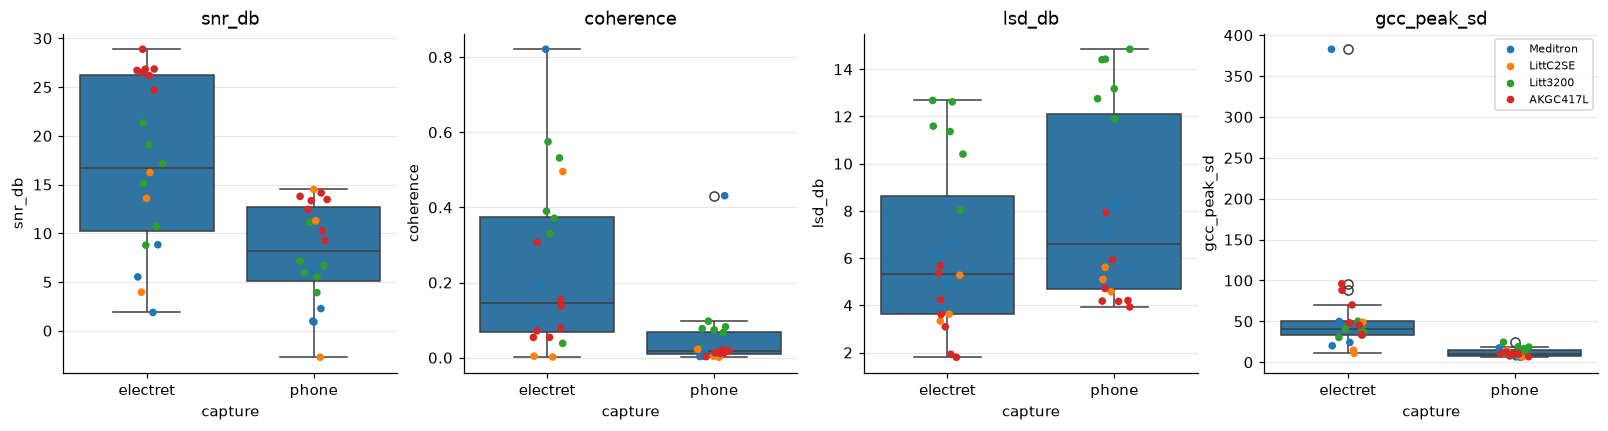

In [2]:
q = takes.groupby('capture')[['lag_sec', 'gcc_peak_sd', 'drift_ppm', 'snr_db', 'coherence', 'lsd_db', 'rms_ratio_db']].agg(['mean', 'std', 'min', 'max'])
q.to_csv(TAB / 'take_quality.csv'); display(q.round(2))
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for i, m in enumerate(['snr_db', 'coherence', 'lsd_db', 'gcc_peak_sd']):
    sns.boxplot(data=takes, x='capture', y=m, ax=ax[i]); sns.stripplot(data=takes, x='capture', y=m, hue='device', ax=ax[i], size=5)
    ax[i].set_title(m); ax[i].get_legend().remove() if i < 3 else ax[i].legend(fontsize=7)
savefig(fig, FIG, 'take_quality')

## 2. Capture transfer functions |H(f)| = sqrt(PSD_take / PSD_original)

PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/replay/transfer_functions.png')

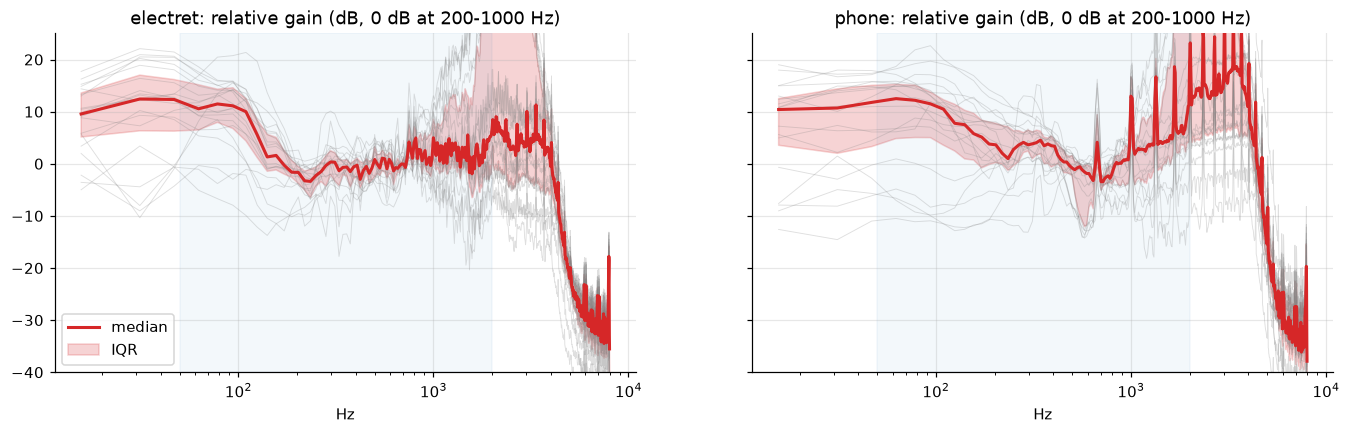

In [3]:
f = tf['freqs']
fig, ax = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for i, c in enumerate(sorted(takes.capture.unique())):
    H = np.array([20 * np.log10(np.maximum(tf[k], 1e-6)) for k in tf.files if k.startswith(c + '__')])
    H = H - np.median(H[:, (f > 200) & (f < 1000)], axis=1, keepdims=True)
    for h in H: ax[i].semilogx(f[1:], h[1:], color='grey', alpha=0.25, lw=0.6)
    ax[i].semilogx(f[1:], np.median(H, 0)[1:], color='C3', lw=2, label='median')
    ax[i].fill_between(f[1:], *np.percentile(H, [25, 75], 0)[:, 1:], color='C3', alpha=0.2, label='IQR')
    ax[i].axvspan(50, 2000, color='C0', alpha=0.05); ax[i].set_title(f'{c}: relative gain (dB, 0 dB at 200-1000 Hz)'); ax[i].set_xlabel('Hz')
ax[0].set_ylim(-40, 25); ax[0].legend()
savefig(fig, FIG, 'transfer_functions')

## 3. Spectrogram: original vs takes vs processed (one test recording)

PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/replay/spectrogram_104_1b1_Al_sc_Litt3200.png')

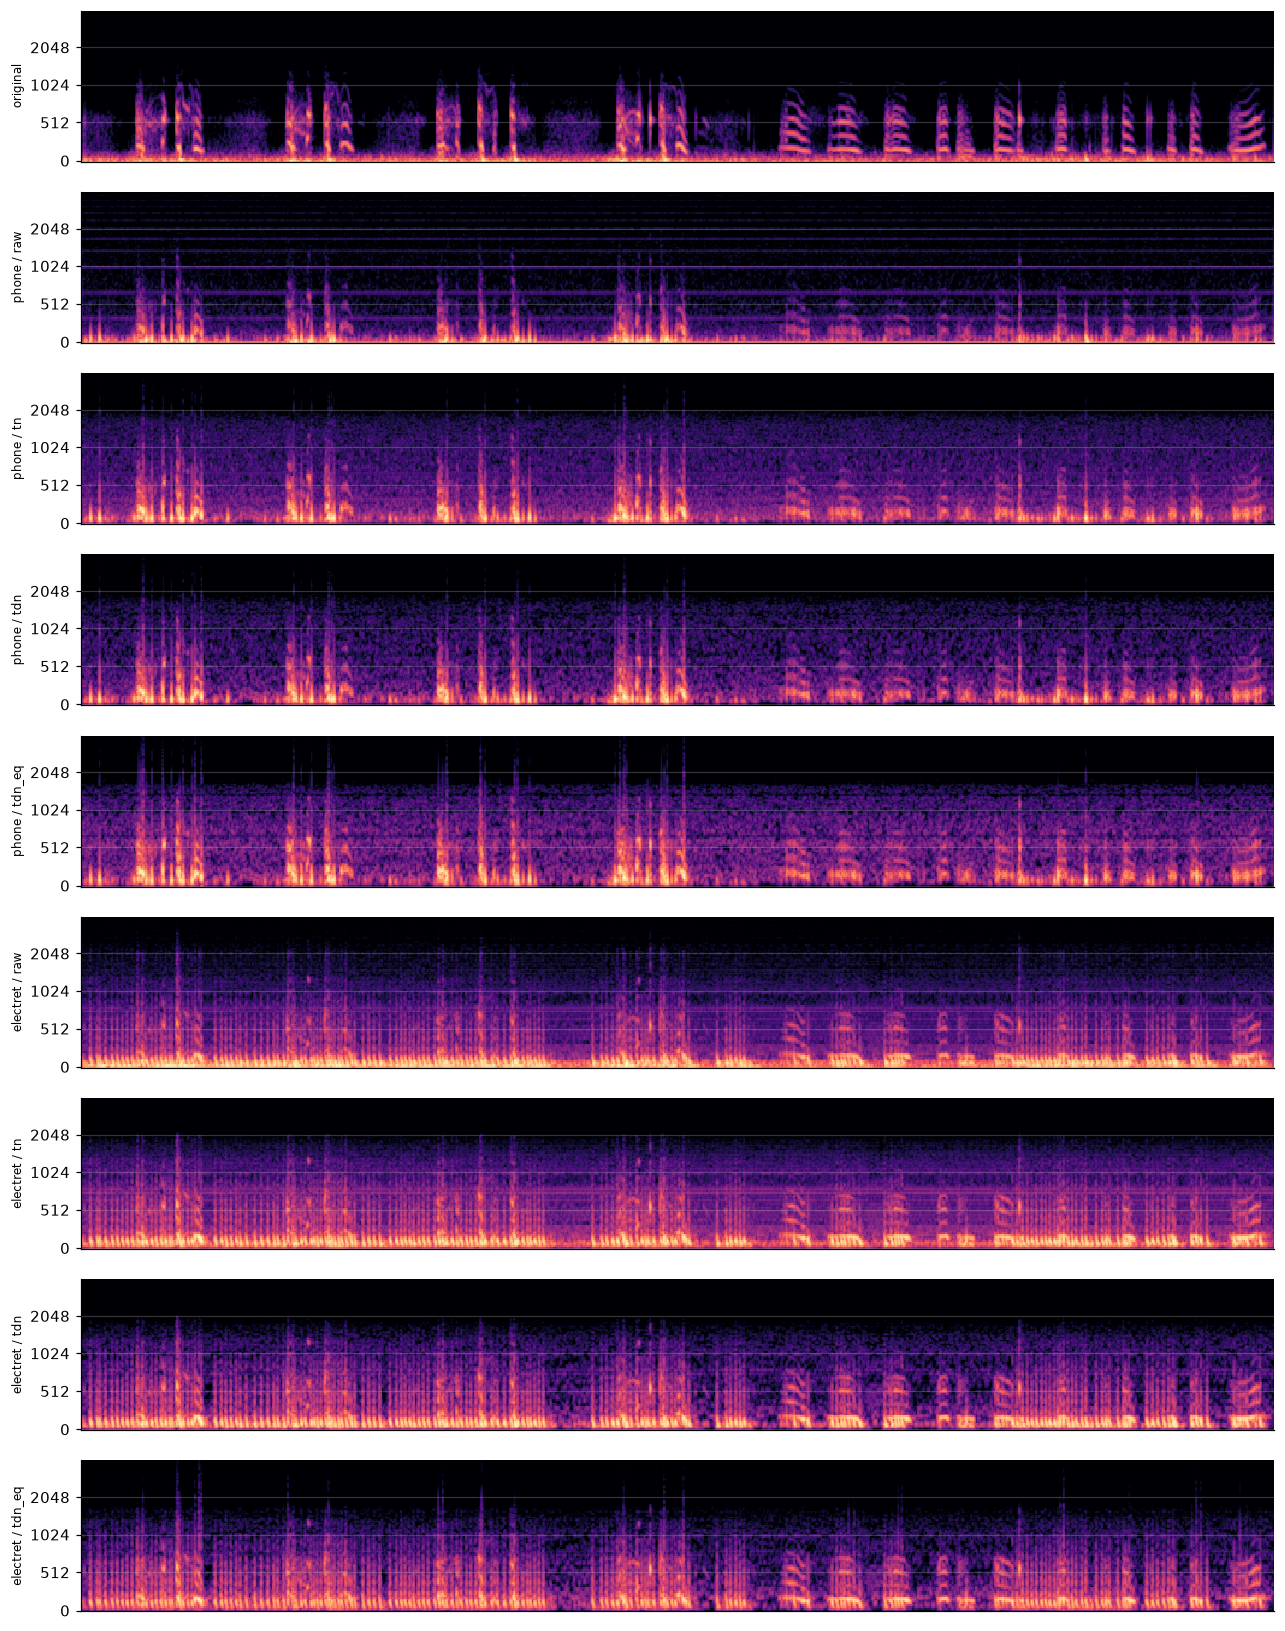

In [4]:
import librosa, librosa.display
from src.processing.audio import load_wav
stem = '104_1b1_Al_sc_Litt3200'
items = [('original', load_wav(DATA / 'raw/icbhi/ICBHI_final_database' / f'{stem}.wav'))]
for c in ['phone', 'electret']:
    for v in ['raw', 'tn', 'tdn', 'tdn_eq']:
        p = RP / 'audio' / c / v / f'{stem}.wav'
        if p.exists(): items.append((f'{c} / {v}', load_wav(p)))
fig, ax = plt.subplots(len(items), 1, figsize=(14, 2.1 * len(items)), sharex=True)
for a, (n, x) in zip(ax, items):
    m = librosa.power_to_db(librosa.feature.melspectrogram(y=x, sr=16000, n_fft=1024, hop_length=256, n_mels=96, fmax=4000), ref=np.max)
    librosa.display.specshow(m, sr=16000, hop_length=256, y_axis='mel', fmax=4000, ax=a, vmin=-70); a.set_ylabel(n, fontsize=8)
savefig(fig, FIG, f'spectrogram_{stem}')

## 4. Agreement with the original prediction and Score, per processing variant

In [5]:
S = summ[summ.capture != 'original']
for split in ['test', 'train']:
    t = S[S.split == split].pivot_table(index=['model', 'variant'], columns='capture', values=['flip_mean', 'flip2_mean', 'score_mean'])
    t.to_csv(TAB / f'variants_{split}.csv'); print(f'== {split}-split takes'); display(t.round(3))
o = summ[summ.capture == 'original'].pivot_table(index=['model', 'variant'], columns='split', values='score_mean'); print('== original audio Score'); display(o.round(2))

== test-split takes


flip2_mean       flip_mean       score_mean       
capture                    electret phone  electret phone   electret  phone
model         variant                                                      
anchor        bp_sc            0.65  0.56      0.69  0.61      33.99  30.06
              dn_eq            0.44  0.31      0.46  0.32      41.26  41.30
              dn_eq12          0.44  0.31      0.46  0.32      41.26  41.30
              dn_sc            0.48  0.49      0.51  0.52      44.56  32.61
              dn_sc_tta        0.48  0.48      0.50  0.51      43.77  32.86
              dn_scd           0.52  0.42      0.55  0.43      45.12  37.36
              eq               0.56  0.43      0.59  0.44      40.22  36.45
              raw              0.69  0.58      0.73  0.63      33.09  28.97
              raw_sc           0.64  0.43      0.68  0.45      37.91  45.45
              raw_sc_rec       0.59  0.41      0.61  0.43      43.64  48.81
              raw_scd          0.67  0.62      0.71  0.66      33.43  26.56
              tdn_eq           0.42  0.29      0.45  0.29      42.14  43.45
              tdn_sc           0.46  0.44      0.49  0.46      40.76  36.90
              tdn_scd          0.49  0.41      0.52  0.43      44.84  39.43
anchor_ens5   bp_sc            0.64  0.55      0.65  0.57      37.56  32.22
              dn_eq            0.43  0.26      0.44  0.26      45.68  42.05
              dn_eq12          0.43  0.26      0.44  0.26      45.68  42.05
              dn_sc            0.46  0.52      0.46  0.53      45.06  34.09
              dn_sc_tta        0.45  0.52      0.45  0.53      45.68  34.09
              dn_scd           0.49  0.40      0.51  0.40      53.52  35.80
              eq               0.56  0.39      0.57  0.39      38.81  37.05
              raw              0.72  0.57      0.74  0.59      35.85  30.34
              raw_sc           0.66  0.41      0.67  0.41      39.60  50.06
              raw_sc_rec       0.59  0.39      0.60  0.39      42.73  49.43
              raw_scd          0.68  0.66      0.69  0.68      38.35  25.34
              tdn_eq           0.42  0.25      0.43  0.25      46.31  42.67
              tdn_sc           0.44  0.39      0.45  0.40      45.06  35.80
              tdn_scd          0.47  0.40      0.48  0.40      48.98  40.97
kd_g4_k1      bp_sc            0.56  0.54      0.60  0.62      42.76  30.53
              dn_eq            0.40  0.32      0.43  0.34      48.00  45.28
              dn_eq12          0.40  0.32      0.43  0.34      48.00  45.28
              dn_sc            0.42  0.47      0.45  0.52      47.78  37.35
              dn_sc_tta        0.42  0.47      0.45  0.52      48.03  35.53
              dn_scd           0.44  0.39      0.47  0.42      50.92  44.30
              eq               0.50  0.39      0.53  0.44      45.10  42.76
              raw              0.61  0.59      0.66  0.68      36.66  26.00
              raw_sc           0.56  0.44      0.59  0.48      45.61  46.66
              raw_sc_rec       0.52  0.43      0.56  0.46      46.58  45.97
              raw_scd          0.60  0.57      0.65  0.66      37.57  26.59
              tdn_eq           0.40  0.32      0.43  0.33      48.25  45.66
              tdn_sc           0.41  0.40      0.44  0.44      47.12  41.98
              tdn_scd          0.43  0.38      0.45  0.41      49.73  44.39
kd_g4_k1_ens5 bp_sc            0.54  0.54      0.58  0.63      42.10  29.09
              dn_eq            0.41  0.32      0.43  0.32      46.93  49.26
              dn_eq12          0.41  0.32      0.43  0.32      46.93  49.26
              dn_sc            0.39  0.46      0.42  0.52      50.85  38.01
              dn_sc_tta        0.40  0.46      0.43  0.52      50.23  38.01
              dn_scd           0.41  0.34      0.44  0.35      49.60  50.68
              eq               0.47  0.37      0.51  0.40      46.48  48.18
              raw              0.61  0.60      0.67  0.69      33.81  24.

== train-split takes


flip2_mean       flip_mean       score_mean       
capture                    electret phone  electret phone   electret  phone
model         variant                                                      
anchor        bp_sc            0.27  0.24      0.42  0.41      60.60  60.18
              dn_eq            0.26  0.31      0.40  0.41      60.79  63.48
              dn_eq12          0.26  0.31      0.40  0.41      60.79  63.48
              dn_sc            0.30  0.27      0.44  0.42      61.70  60.07
              dn_sc_tta        0.30  0.26      0.45  0.41      61.49  60.57
              dn_scd           0.27  0.27      0.43  0.40      60.40  64.83
              eq               0.25  0.24      0.41  0.40      57.83  63.15
              raw              0.29  0.29      0.46  0.45      58.73  57.64
              raw_sc           0.25  0.44      0.39  0.52      64.67  59.44
              raw_sc_rec       0.25  0.43      0.42  0.52      58.45  59.53
              raw_scd          0.25  0.31      0.41  0.46      62.74  56.38
              tdn_eq           0.28  0.34      0.41  0.41      60.12  65.18
              tdn_sc           0.31  0.27      0.45  0.39      61.26  66.76
              tdn_scd          0.27  0.31      0.43  0.42      60.84  64.36
anchor_ens5   bp_sc            0.23  0.24      0.40  0.42      63.41  57.98
              dn_eq            0.24  0.29      0.36  0.38      63.84  68.11
              dn_eq12          0.24  0.29      0.36  0.38      63.84  68.11
              dn_sc            0.31  0.25      0.47  0.40      60.36  61.94
              dn_sc_tta        0.28  0.24      0.44  0.40      62.11  62.68
              dn_scd           0.25  0.27      0.40  0.40      62.68  64.88
              eq               0.25  0.23      0.43  0.39      54.90  63.55
              raw              0.29  0.26      0.46  0.42      58.29  60.19
              raw_sc           0.23  0.47      0.38  0.53      65.17  58.77
              raw_sc_rec       0.23  0.47      0.40  0.55      60.47  57.16
              raw_scd          0.25  0.33      0.42  0.47      60.19  54.47
              tdn_eq           0.24  0.29      0.35  0.36      66.19  69.72
              tdn_sc           0.31  0.24      0.44  0.34      63.58  72.21
              tdn_scd          0.23  0.28      0.39  0.41      64.29  65.48
kd_g4_k1      bp_sc            0.26  0.25      0.43  0.46      57.60  51.91
              dn_eq            0.26  0.29      0.43  0.42      56.01  59.45
              dn_eq12          0.26  0.29      0.43  0.42      56.01  59.45
              dn_sc            0.27  0.23      0.44  0.42      59.99  56.68
              dn_sc_tta        0.28  0.24      0.44  0.43      59.49  56.16
              dn_scd           0.25  0.26      0.43  0.39      58.75  64.03
              eq               0.24  0.23      0.43  0.42      54.75  58.95
              raw              0.29  0.28      0.47  0.47      58.33  50.06
              raw_sc           0.25  0.30      0.40  0.42      63.83  64.99
              raw_sc_rec       0.27  0.38      0.43  0.49      56.37  60.49
              raw_scd          0.23  0.29      0.39  0.46      64.38  54.26
              tdn_eq           0.26  0.30      0.42  0.41      57.36  63.54
              tdn_sc           0.26  0.21      0.43  0.37      61.75  67.19
              tdn_scd          0.26  0.23      0.43  0.37      59.16  68.22
kd_g4_k1_ens5 bp_sc            0.26  0.24      0.43  0.46      56.37  52.41
              dn_eq            0.26  0.28      0.44  0.41      53.28  59.59
              dn_eq12          0.26  0.28      0.44  0.41      53.28  59.59
              dn_sc            0.24  0.22      0.41  0.40      62.53  59.00
              dn_sc_tta        0.24  0.20      0.41  0.40      62.53  59.00
              dn_scd           0.24  0.26      0.42  0.40      59.45  64.15
              eq               0.25  0.20      0.46  0.41      50.93  58.86
              raw              0.25  0.27      0.42  0.47      61.66  50.

== original audio Score


split                         test   train
model         variant                     
anchor        original       56.34  100.00
              original_nosc  53.36   92.51
anchor_ens5   original       58.47  100.00
              original_nosc  52.05   92.98
kd_g4_k1      original       63.81   99.82
              original_nosc  60.30   89.26
kd_g4_k1_ens5 original       63.81  100.00
              original_nosc  55.97   91.23

PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/replay/variants_kd_g4_k1.png')

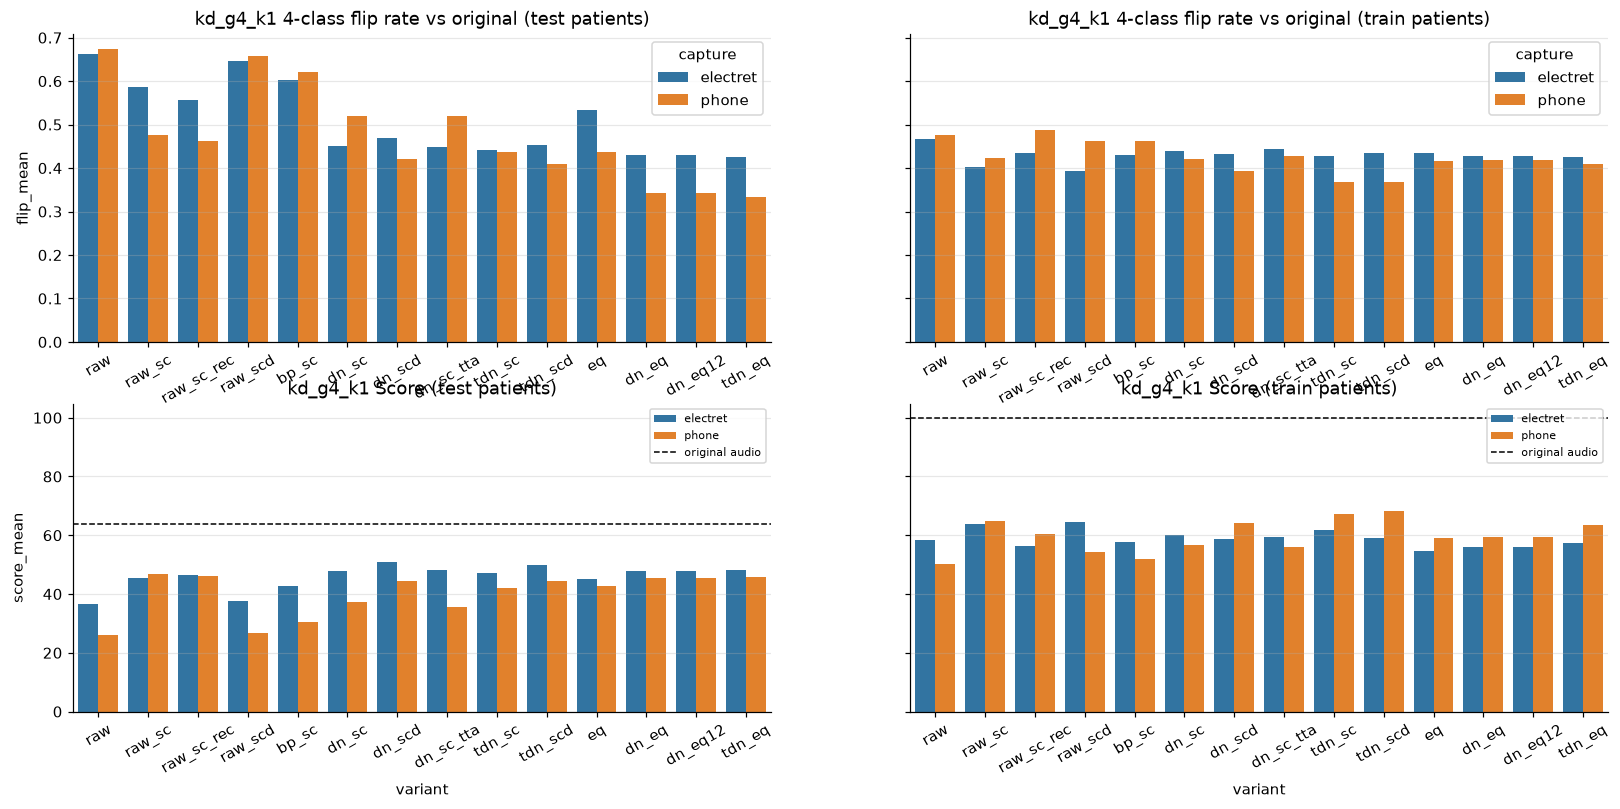

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(18, 8), sharey='row')
for j, split in enumerate(['test', 'train']):
    g = S[(S.split == split) & (S.model == 'kd_g4_k1')]
    sns.barplot(data=g, x='variant', y='flip_mean', hue='capture', order=VARIANTS, ax=ax[0, j]); ax[0, j].set_title(f'kd_g4_k1 4-class flip rate vs original ({split} patients)')
    sns.barplot(data=g, x='variant', y='score_mean', hue='capture', order=VARIANTS, ax=ax[1, j]); ax[1, j].set_title(f'kd_g4_k1 Score ({split} patients)')
    for a in ax[:, j]: a.tick_params(axis='x', rotation=30)
    o = summ[(summ.capture == 'original') & (summ.variant == 'original') & (summ.split == split) & (summ.model == 'kd_g4_k1')].score_mean
    ax[1, j].axhline(o.iloc[0], color='k', ls='--', lw=1, label='original audio'); ax[1, j].legend(fontsize=7)
savefig(fig, FIG, 'variants_kd_g4_k1')

### Seed ensemble and normal-vs-abnormal agreement

`flip2` = share of cycles whose normal/abnormal decision changes against the original; `_ens5` = mean softmax over seeds.

In [7]:
t = S[(S.split == 'test') & S.model.isin(['kd_g4_k1', 'kd_g4_k1_ens5', 'anchor', 'anchor_ens5'])]
t = t.pivot_table(index='variant', columns=['model', 'capture'], values='flip2_mean').reindex(VARIANTS)
t.to_csv(TAB / 'flip2_test.csv'); t.round(3)

model        anchor       anchor_ens5       kd_g4_k1       kd_g4_k1_ens5      
capture    electret phone    electret phone electret phone      electret phone
variant                                                                       
raw            0.69  0.58        0.72  0.57     0.61  0.59          0.61  0.60
raw_sc         0.64  0.43        0.66  0.41     0.56  0.44          0.55  0.44
raw_sc_rec     0.59  0.41        0.59  0.39     0.52  0.43          0.52  0.40
raw_scd        0.67  0.62        0.68  0.66     0.60  0.57          0.57  0.60
bp_sc          0.65  0.56        0.64  0.55     0.56  0.54          0.54  0.54
dn_sc          0.48  0.49        0.46  0.52     0.42  0.47          0.39  0.46
dn_scd         0.52  0.42        0.49  0.40     0.44  0.39          0.41  0.34
dn_sc_tta      0.48  0.48        0.45  0.52     0.42  0.47          0.40  0.46
tdn_sc         0.46  0.44        0.44  0.39     0.41  0.40          0.37  0.39
tdn_scd        0.49  0.41        0.47  0.40     0.43  0.38          0.41  0.36
eq             0.56  0.43        0.56  0.39     0.50  0.39          0.47  0.37
dn_eq          0.44  0.31        0.43  0.26     0.40  0.32          0.41  0.32
dn_eq12        0.44  0.31        0.43  0.26     0.40  0.32          0.41  0.32
tdn_eq         0.42  0.29        0.42  0.25     0.40  0.32          0.41  0.31

## 5. Automatic choice (selected on training-split takes, evaluated on test-split takes)

In [8]:
ch = pd.DataFrame(sel['choice']).T
ch.to_csv(TAB / 'auto_choice.csv'); ch

,chosen,test_flip,test_score,raw_sc_test_flip,raw_sc_test_score
anchor/electret,raw_sc,0.67,37.91,0.67,37.91
anchor/phone,tdn_sc,0.46,36.9,0.45,45.45
anchor_ens5/electret,tdn_eq,0.43,46.31,0.67,39.6
anchor_ens5/phone,tdn_sc,0.4,35.8,0.41,50.06
kd_g4_k1/electret,raw_scd,0.65,37.57,0.59,45.61
kd_g4_k1/phone,tdn_sc,0.44,41.98,0.48,46.66
kd_g4_k1_ens5/electret,raw_scd,0.63,35.06,0.59,45.4
kd_g4_k1_ens5/phone,tdn_sc,0.42,43.01,0.47,48.35


## 6. Per-take flip rate vs signal quality (kd_g4_k1, raw_sc)

PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/replay/flip_vs_quality.png')

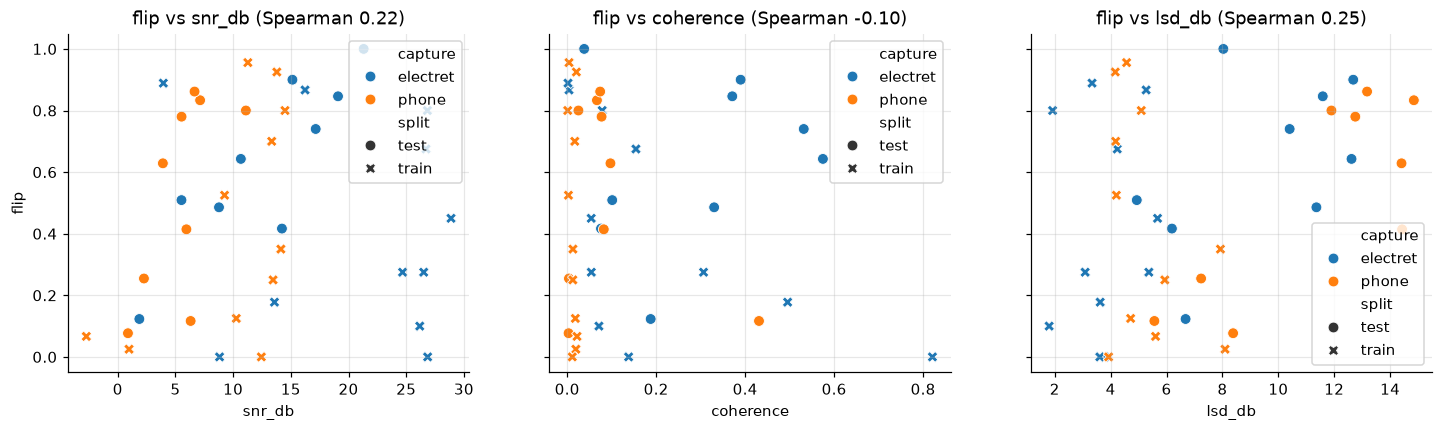

In [9]:
k = cyc[(cyc.model == 'kd_g4_k1') & (cyc.variant == 'raw_sc')].groupby(['capture', 'stem']).flip.mean().rename('flip').reset_index()
k = k.merge(takes, on=['capture', 'stem'])
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for i, m in enumerate(['snr_db', 'coherence', 'lsd_db']):
    sns.scatterplot(data=k, x=m, y='flip', hue='capture', style='split', ax=ax[i], s=50)
    ax[i].set_title(f'flip vs {m} (Spearman {k[[m, "flip"]].corr("spearman").iloc[0, 1]:.2f})')
savefig(fig, FIG, 'flip_vs_quality')

## 7. Class-level change: confusion of original vs replay predictions (kd_g4_k1, chosen variant)

PosixPath('/home/namdp15/Workspace/Personal/KHKT-CVA-2026/auscult-trust/outputs/figures/replay/confusion_original_vs_replay.png')

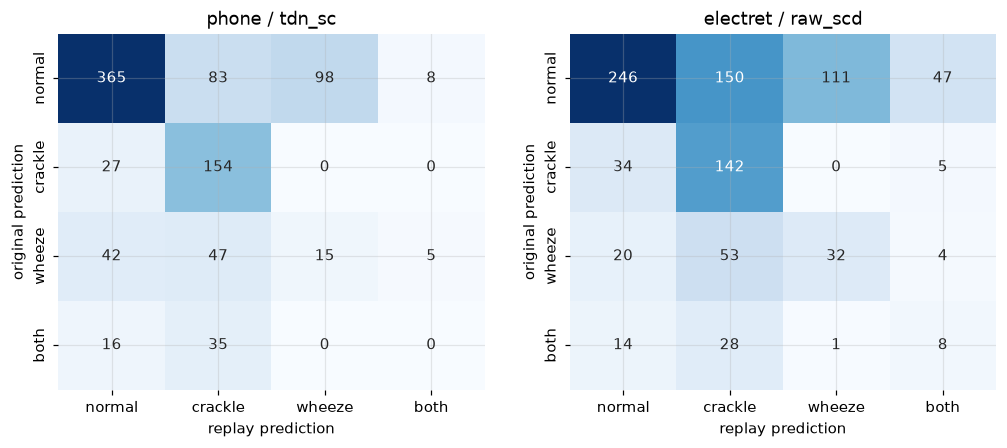

In [10]:
from sklearn.metrics import confusion_matrix
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for i, c in enumerate(['phone', 'electret']):
    v = sel['choice'][f'kd_g4_k1/{c}']['chosen']
    g = cyc[(cyc.model == 'kd_g4_k1') & (cyc.capture == c) & (cyc.variant == v)]
    cm = confusion_matrix(g.pred_orig, g.pred, labels=range(4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[i])
    ax[i].set_title(f'{c} / {v}'); ax[i].set_xlabel('replay prediction'); ax[i].set_ylabel('original prediction')
savefig(fig, FIG, 'confusion_original_vs_replay')